## Кластеризация

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
data=pd.read_excel('data for clustering.xls')

In [4]:
data.head()

,target,age,educ,work_exp,interest,coffee,boss_educ,passport,green,floor,children,climate,offhour,dist,salary,heigh,lunch
0,0,50,4,27,8,1.3,1,0,2,3,2,0,0,10.6,1,176,226
1,0,30,3,10,0,0.0,6,1,2,3,0,0,0,11.5,0,186,226
2,0,43,3,22,7,1.9,6,1,1,5,0,3,0,12.8,1,166,238
3,0,58,3,31,7,2.0,4,0,3,3,1,1,0,15.2,1,180,216
4,1,40,3,23,7,0.0,6,1,3,2,0,0,0,16.1,1,180,286


In [5]:
data.describe()

,target,age,educ,work_exp,interest,coffee,boss_educ,passport,green,floor,children,climate,offhour,dist,salary,heigh,lunch
count,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000,984.000000
mean,0.320122,41.108740,2.741870,19.360772,5.137195,0.909654,3.819106,0.377033,2.455285,4.945122,1.271341,1.809959,0.494919,12.754065,0.440041,176.913618,253.551829
std,0.466760,12.394227,1.287089,12.485227,2.973344,0.976238,1.501373,0.484890,1.305763,4.468385,1.231393,1.343937,0.500228,4.696912,0.496644,8.215167,56.037621
min,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.300000,0.000000,153.000000,92.000000
25%,0.000000,32.000000,2.000000,9.000000,3.000000,0.000000,3.000000,0.000000,1.000000,2.000000,0.000000,1.000000,0.000000,10.700000,0.000000,171.000000,217.000000
50%,0.000000,40.500000,3.000000,18.000000,5.000000,0.500000,4.000000,0.000000,2.000000,4.000000,1.000000,2.000000,0.000000,12.200000,0.000000,177.000000,252.000000
75%,1.000000,50.000000,4.000000,28.000000,8.000000,1.800000,5.000000,1.000000,3.000000,6.000000,2.000000,3.000000,1.000000,13.600000,1.000000,182.000000,290.000000
max,1.000000,80.000000,6.000000,61.000000,10.000000,3.600000,7.000000,1.000000,5.000000,29.000000,4.000000,4.000000,1.000000,40.600000,1.000000,198.000000,444.000000


In [6]:
data.columns

Index(['target', 'age', 'educ', 'work_exp', 'interest', 'coffee', 'boss_educ',
       'passport', 'green', 'floor', 'children', 'climate', 'offhour', 'dist',
       'salary', 'heigh', 'lunch'],
      dtype='object')

* target – сотрудник уволится в следующем году (0-нет, 1-да)
* age - возраст
* educ - образование (1-начальное, 2-среднее, 3 -неоконченное высшее, 4-два и более высших образования, 5-кандидат наук, 6-доктор наук)
* work_exp – стаж работы (лет)
* interest – оценка сотрудником интереса к работе (от 0 до 10)
* coffee - среднее количество чашек кофе, выпиваемых сотрудником за рабочий день
* boss_educ - образование руководителя (1-начальное, 2-среднее, 3 -неоконченное высшее, 4-два и более высших образования, 5-кандидат наук, 6-доктор наук)
* passport - наличие загранпаспорта у сотрудника (1-есть, 0 -нет)
* green - степень озеленения офиса (от 1 до 5)
* floor – этаж работы
* children – количество детей у сотрудника
* climate - удовлетворенность рабочей атмосферой (от 0 до 4)
* offhour – наличие переработок (1-да, 0 -нет)
* dist – расстояние до работы
* salary – удовлетворенность заработной платой (1-да, 0 -нет)
* height - рост сотрудника
* lunch - средняя цена бизнес-ланча в офисе

**Цель кластеризации - разработка мер повышения эффективности сотрудников компании**

### Предварительный анализ данных

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 984 entries, 0 to 983
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   target     984 non-null    int64  
 1   age        984 non-null    int64  
 2   educ       984 non-null    int64  
 3   work_exp   984 non-null    int64  
 4   interest   984 non-null    int64  
 5   coffee     984 non-null    float64
 6   boss_educ  984 non-null    int64  
 7   passport   984 non-null    int64  
 8   green      984 non-null    int64  
 9   floor      984 non-null    int64  
 10  children   984 non-null    int64  
 11  climate    984 non-null    int64  
 12  offhour    984 non-null    int64  
 13  dist       984 non-null    float64
 14  salary     984 non-null    int64  
 15  heigh      984 non-null    int64  
 16  lunch      984 non-null    int64  
dtypes: float64(2), int64(15)
memory usage: 130.8 KB


In [8]:
data.isnull().sum()
# Видим, что нет нулевых значений ни в одной из переменных, следовательно, нет необходимости заполнять пропуски. 

target       0
age          0
educ         0
work_exp     0
interest     0
coffee       0
boss_educ    0
passport     0
green        0
floor        0
children     0
climate      0
offhour      0
dist         0
salary       0
heigh        0
lunch        0
dtype: int64

In [9]:
# Поиск абсолютных дубликатов
data.duplicated().sum()

0

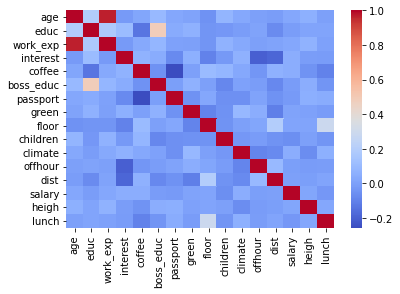

In [10]:
# Так как в данных нет пропусков и дупликатов, можем перейти к анализу матрицы корреляций и выбору переменных.
X=data.drop(columns=['target'])
sns.heatmap(X.corr(), cmap='coolwarm');

Выбранные переменные: **green, educ, work_exp, salary, climate**. 

Они практически не коррелируют между собой, так что хорошо подойдут для поставленной задачи. 

Green - степень озеленения офиса. Как известно, растения не только производят кислород, но и поднимают настроение, увеличивают рабочий настрой. Работники более "зеленых" офисов должны работать эффективнее, чем их коллеги из офисов без растений. 

Educ - образование работника, неоднозначный показатель. С одной стороны, работники с низким уровнем образования, будут сильнее замотивированы узнавать больше о своей работе, чтобы достичь уровня своих более образованных коллег, из-за чего эффективность работы будет высокая. С другой стороны, часто необразованные люди являются таковыми из-за своей лени и нежелания учиться, так что и на работе они вряд ли будут сильно эффективны. Работникам с высоким образованием, наоборот, требуется больше мотивации (в том числе денежной), чтобы удержать их на вакансии. Ведь если их что-то не устроит, они всегда могут пойти на рынок труда и без проблем найти новую работу с теми же (или даже лучшими) условиями. 

Work_exp - стаж работы. С уверенностью можно сказать, что сотрудники с маленьким стажем работы показывают большую эффективность, чем их коллеги, работающие на одном месте уже много лет. Это связано с тем, что новичкам еще предстоит проявить себя, закрепиться в компании и подняться по карьерной лестнице, тогда как более опытные коллеги уже это сделали, их все устраивает, новых целей для достижения может не быть, поэтому мотивация низкая. 

Salary - удовлетворенность заработной платой. Пожалуй, самый понятный показатель. Чем больше зарплата сотрудника, тем эффективнее он будет работать, ведь такую зарплату терять не хочется. 

Climate - удовлетворенность рабочей атмосферой, является очень важным и недооцененным показателем. Если работнику комфортно в компании коллег, руководства, то он будет с удовольствием приходить на работу и эффективно работать.

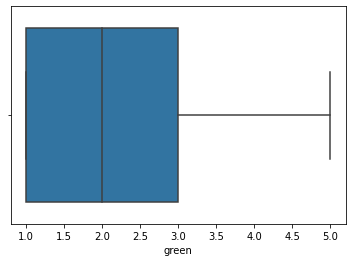

In [11]:
# Удаление выбросов
sns.boxplot(data['green'])

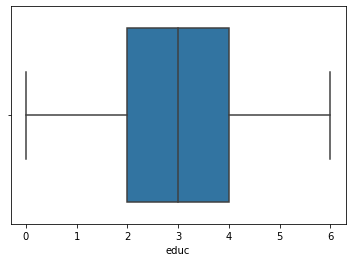

In [12]:
sns.boxplot(data['educ'])

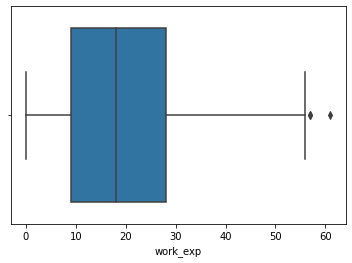

In [13]:
sns.boxplot(data['work_exp'])

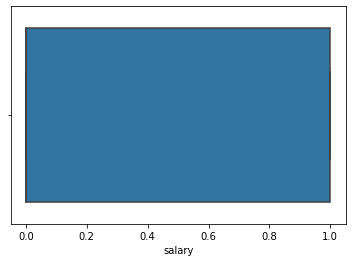

In [14]:
sns.boxplot(data['salary'])

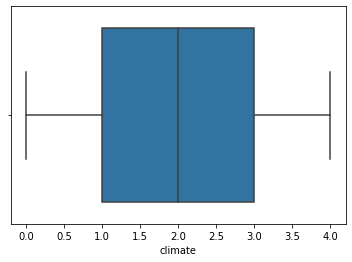

In [15]:
sns.boxplot(data['climate'])

In [16]:
def remove_outlier(data_in, col_name):
    q1 = data_in[col_name].quantile(0.25)
    q3 = data_in[col_name].quantile(0.75)
    iqr = q3-q1 #Interquartile range
    fence_low  = q1-1.5*iqr
    fence_high = q3+1.5*iqr
    data_out = data_in.loc[(data_in[col_name] > fence_low) & (data_in[col_name] < fence_high)]
    return data_out

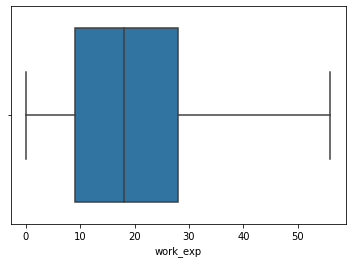

In [17]:
data = remove_outlier(data, 'work_exp')
sns.boxplot(data['work_exp'])

Выбросы удалены, переходим к стандартизации.

In [18]:
selected_cols = [
    'green',
    'educ',
    'work_exp',
    'salary',
    'climate'
    ]

### Стандартизация данных методом Standard Scaler

In [19]:
from sklearn.preprocessing import StandardScaler
scaler_standard = StandardScaler()
scaler_standard.fit(data)
data_standard = scaler_standard.transform(data)

In [20]:
df_std = pd.DataFrame(data_standard, columns = data.columns)
print(df_std)

       target       age      educ  work_exp  interest    coffee  boss_educ  \
0   -0.687730  0.735544  0.976487  0.630268  0.964064  0.401927  -1.876095   
1   -0.687730 -0.898443  0.199574 -0.750757 -1.725583 -0.931175   1.454432   
2   -0.687730  0.163649  0.199574  0.224084  0.627859  1.017205   1.454432   
3   -0.687730  1.389139  0.199574  0.955215  0.627859  1.119752   0.122221   
4    1.454058 -0.081450  0.199574  0.305321  0.627859 -0.931175   1.454432   
..        ...       ...       ...       ...       ...       ...        ...   
976 -0.687730 -0.735044 -1.354252 -0.913230 -0.716965  0.401927   0.122221   
977 -0.687730  0.898943  0.199574  1.198925  0.291653  0.401927   0.788326   
978 -0.687730  1.307440  0.199574  1.280162  1.300270  1.119752  -1.876095   
979 -0.687730 -0.735044 -0.577339 -0.750757  0.627859 -0.931175  -0.543884   
980  1.454058 -0.489946  0.199574 -0.669520 -1.389377 -0.931175   0.788326   

     passport     green     floor  children   climate   offhour

### Стандартизация данных методом MinMax Scaler

In [21]:
from sklearn.preprocessing import MinMaxScaler
scaler_minmax = MinMaxScaler()
scaler_minmax.fit(data)
data_minmax = scaler_minmax.transform(data)

In [22]:
# df_minmax=
df_minmax = pd.DataFrame(data_minmax, columns = data.columns)
print(df_minmax)

     target       age      educ  work_exp  interest    coffee  boss_educ  \
0       0.0  0.568966  0.666667  0.482143       0.8  0.361111   0.142857   
1       0.0  0.224138  0.500000  0.178571       0.0  0.000000   0.857143   
2       0.0  0.448276  0.500000  0.392857       0.7  0.527778   0.857143   
3       0.0  0.706897  0.500000  0.553571       0.7  0.555556   0.571429   
4       1.0  0.396552  0.500000  0.410714       0.7  0.000000   0.857143   
..      ...       ...       ...       ...       ...       ...        ...   
976     0.0  0.258621  0.166667  0.142857       0.3  0.361111   0.571429   
977     0.0  0.603448  0.500000  0.607143       0.6  0.361111   0.714286   
978     0.0  0.689655  0.500000  0.625000       0.9  0.555556   0.142857   
979     0.0  0.258621  0.333333  0.178571       0.7  0.000000   0.428571   
980     1.0  0.310345  0.500000  0.196429       0.1  0.000000   0.714286   

     passport  green     floor  children  climate  offhour      dist  salary  \
0      

In [23]:
data.columns

Index(['target', 'age', 'educ', 'work_exp', 'interest', 'coffee', 'boss_educ',
       'passport', 'green', 'floor', 'children', 'climate', 'offhour', 'dist',
       'salary', 'heigh', 'lunch'],
      dtype='object')

### Данные для кластеризации

In [24]:
data_clust=df_std[['green', 'educ', 'work_exp', 'salary', 'climate']]

In [25]:
data_clust.corr()

,green,educ,work_exp,salary,climate
green,1.000000,0.066557,0.004056,0.014255,0.096816
educ,0.066557,1.000000,0.178654,-0.007248,-0.008123
work_exp,0.004056,0.178654,1.000000,0.017710,0.038642
salary,0.014255,-0.007248,0.017710,1.000000,0.049742
climate,0.096816,-0.008123,0.038642,0.049742,1.000000


In [ ]:
# Необходимо, чтобы не было сильно коррелированных показателей
# Данное условие выполнено.

### Выбираем число кластеров

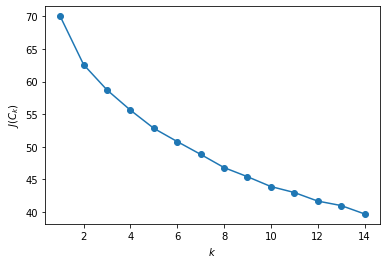

In [26]:
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 15):
    kmeans = KMeans(n_clusters=k, random_state=42).fit(data_clust)
    inertia.append(np.sqrt(kmeans.inertia_))

plt.plot(range(1, 15), inertia, marker='o');
plt.xlabel('$k$')
plt.ylabel('$J(C_k)$');

По данному графику сложно сделать вывод о необходимом количестве кластеров. Предположительно, количество калстеров невелико: можно предположить, что оно должно быть меньше 6, ондако посмотрим на другой график, чтобы сделать окончательный вывод. 

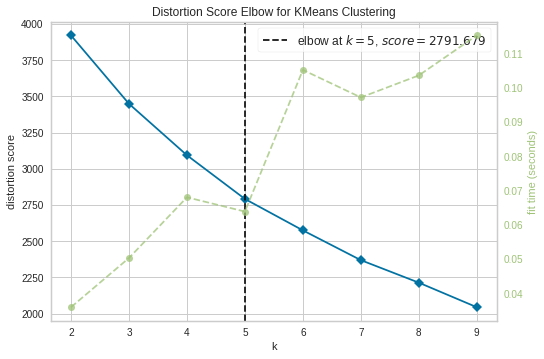

In [27]:
from yellowbrick.cluster import KElbowVisualizer

model = KMeans(random_state=1)
visualizer = KElbowVisualizer(model, k=(2,10))

visualizer.fit(data_clust)
visualizer.show()
plt.show()

Данный график автоматически выдает нам оптимальное количсетво кластеров. В нашем случае, оптимальное число k = 5. Это оправдывает наше предыдущее предположение. 

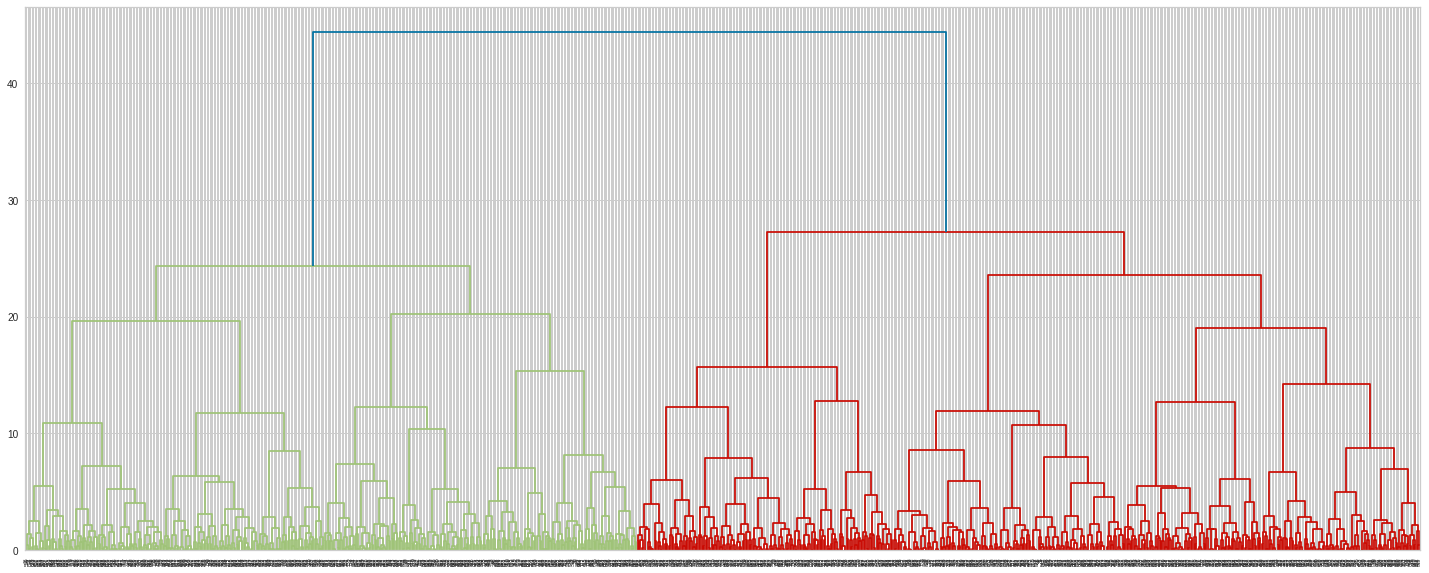

In [28]:
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(data_clust, 'ward')
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)

Согласно дендрограмме иерархической кластеризации, предполагается, что оптимальным количством кластеров будет 6 (можем мысленно провести линию на уровне 21 по оси Y, чтобы определить количество кластеров). Опять же, это число попадает в наш изначально предположенный диапазон. Продолжим анализ, чтобы прийти к окночательному выводу. 

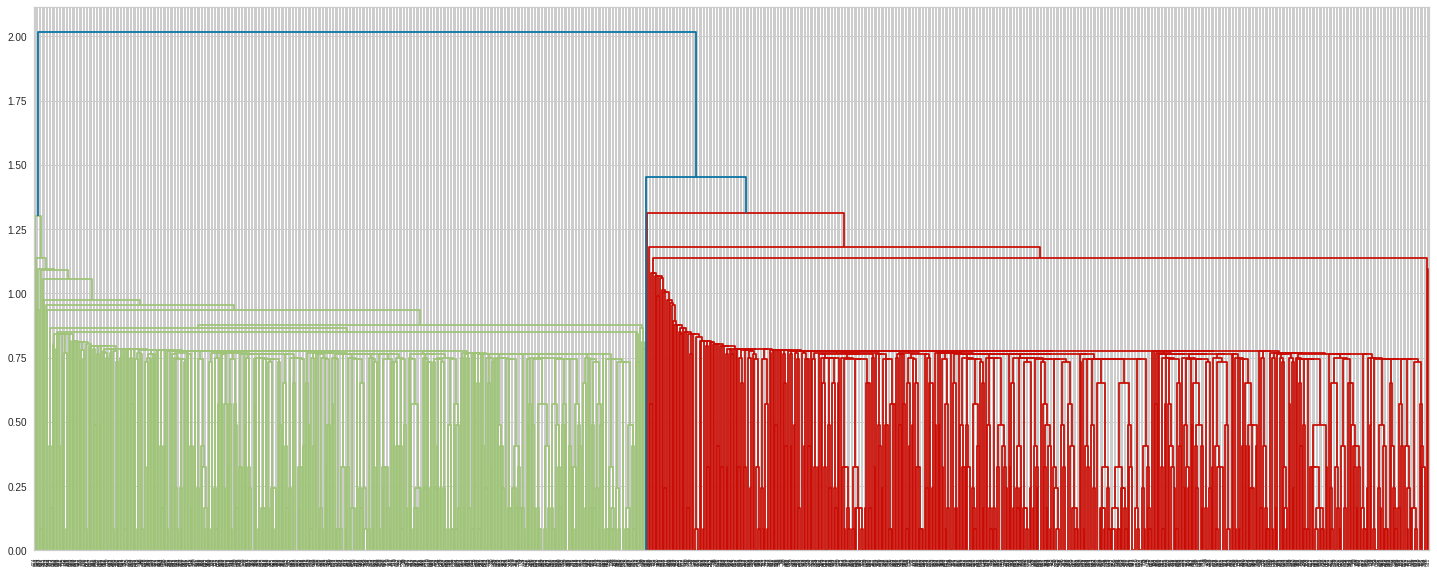

In [29]:
Z = linkage(data_clust, 'single')
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)

Данный график немного сложнее для анализа, однако смеем предположить, что оптимальным количеством станет 4 кластера, если проводить разрез по линии 125 по оси у. 

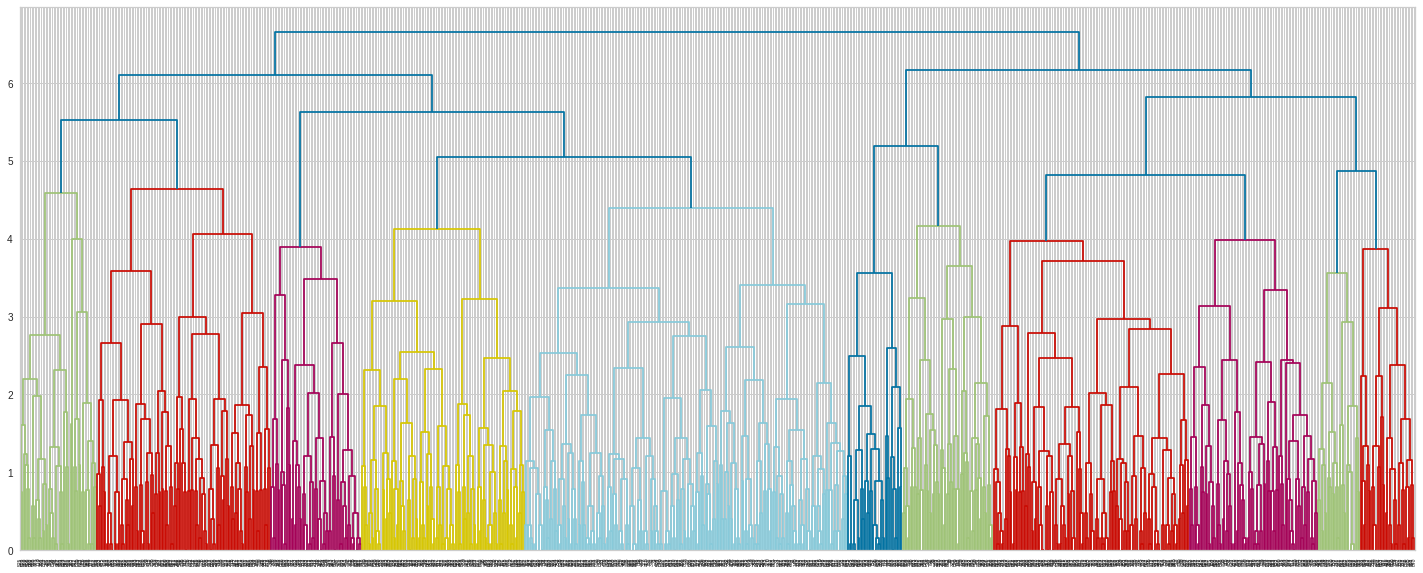

In [ ]:
Z = linkage(data_clust, 'complete')
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)

В данном случае самым здравым решением будет провести разрез по линии 6 на оси у, так как в остальных случаях колчиство кластеров слишком велико и противоречит нашему изначальному предположению. 

**Вывод:** нами было принято решение остановиться на 5 кластерах, не только по тому, что второй график автоматичсеки (с помощью метода локтя) определил данное количество как оптимальное, но и потому, что данное значение является средним среди всех остальных, полученных при анализе других графиков. 

Среднее значение силуэта для 5 кластеров: 0.19


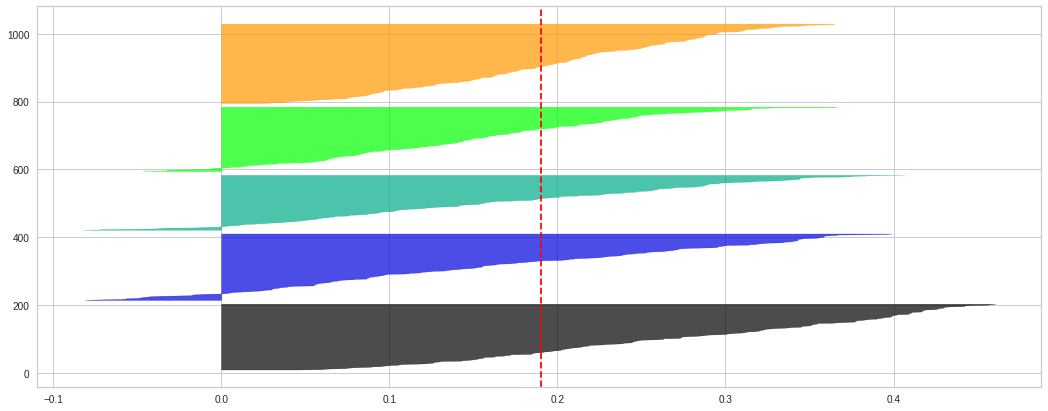

In [30]:
from matplotlib import cm
from sklearn.metrics import silhouette_score, silhouette_samples
fig, (ax1) = plt.subplots(1, 1)
fig.set_size_inches(18, 7)


clusterer = KMeans(n_clusters=5, random_state=10)
cluster_labels = clusterer.fit_predict(data_clust)

silhouette_avg = silhouette_score(data_clust, cluster_labels)
print("Среднее значение силуэта для 5 кластеров:", round(silhouette_avg,2))

sample_silhouette_values = silhouette_samples(data_clust, cluster_labels)

y_lower = 10
for i in range(0, 5):
    ith_cluster_silhouette_values = \
         sample_silhouette_values[cluster_labels == i]

    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 5)
    ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)
    y_lower = y_upper + 10

ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

plt.show()

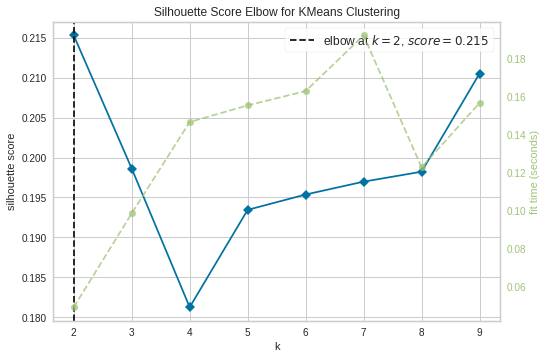

In [31]:
from yellowbrick.cluster import KElbowVisualizer
model = KMeans(random_state=1)
visualizer = KElbowVisualizer(model, k=(2,10), metric='silhouette')

visualizer.fit(data_clust)
visualizer.show()
plt.show()

По графику силуэтов видно, что большинство значений находятся в положительной зоне, значит, они далеко от соседних кластеров и, скорее всего, определены правильно. Тем не менее, есть некоторые значения в отрицательной зоне, которые могут быть ошибочно отнесены к неверному кластеру. Опять же, минимальные значения доходят лишь до -0,1. Это можно считать несущественным отклонением от границы принятия решений, поэтому будем считать, что кластеры определены верно.






### Кластеризация k-means

In [32]:
KM_5_clusters = KMeans(n_clusters=5, init='k-means++').fit(data_clust)

KM5_clustered = data_clust.copy()
KM5_clustered.loc[:,'Cluster'] = KM_5_clusters.labels_ 

In [33]:
KM_5_clusters.cluster_centers_

array([[-0.37675897, -0.31005235, -0.48096118,  1.13198734, -0.49052073],
       [-0.53196343,  0.71131289,  1.105527  , -0.55756069, -0.28228948],
       [ 1.14195044,  0.26244548, -0.15580317, -0.8834021 ,  0.31322067],
       [ 0.59440257,  0.24156921,  0.38260558,  1.13198734,  0.78888112],
       [-0.57374183, -0.59366056, -0.51933427, -0.8834021 , -0.19350555]])

In [42]:
# Ваш код: график средних
# График средних
def get_centroid(cluster):
  cluster_ary = np.asarray(cluster)
  centroid = cluster_ary.mean(axis = 0)
  return centroid

<function matplotlib.pyplot.show(*args, **kw)>

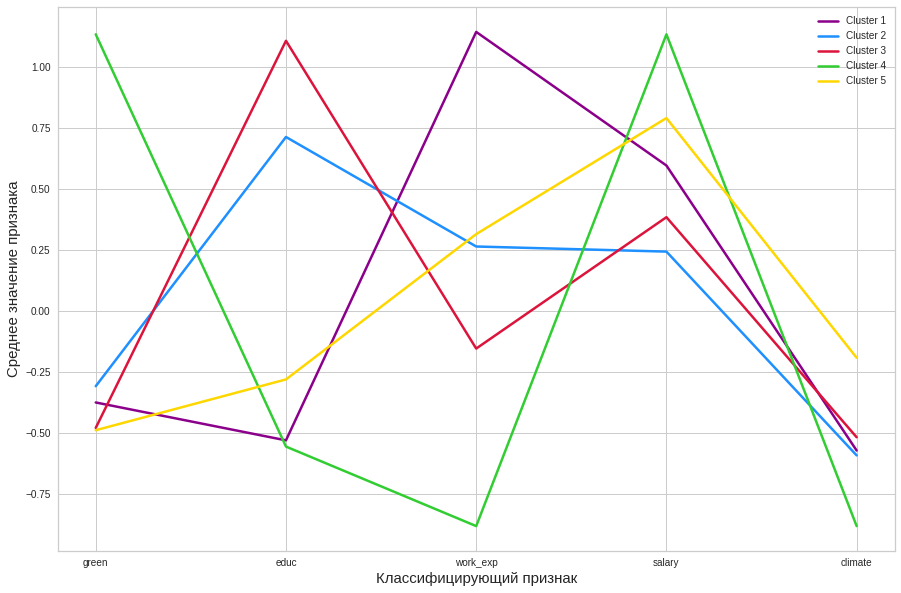

In [43]:
x = data_clust
n_clusters = 5
db_clusters = pd.Series([x[KM_5_clusters.labels_==n] for n in range(n_clusters)])
db_centroids = db_clusters.map(get_centroid)
cent_green, cent_educ, cent_work_exp, cent_salary, cent_climate = zip(*db_centroids)
centroids_pd = pd.DataFrame({'green':cent_green, 'educ':cent_educ, 'work_exp':cent_work_exp, 'salary':cent_salary, 'climate':cent_climate})
# График средних
x = ['green', 'educ', 'work_exp', 'salary', 'climate']
y = cent_green
y1 = cent_educ
y2 = cent_work_exp
y3 = cent_salary
y4 = cent_climate

plt.figure(figsize=(15,10))

plt.plot(x, y, color="#8B008B", label='Cluster 1', linewidth = 2.5)
plt.plot(x, y1, color="dodgerblue", label='Cluster 2', linewidth = 2.5)
plt.plot(x, y2, color="crimson", label='Cluster 3', linewidth = 2.5)
plt.plot(x, y3, color="limegreen", label='Cluster 4', linewidth = 2.5)
plt.plot(x, y4, color="gold", label='Cluster 5', linewidth = 2.5)

plt. xlabel ('Классифицирующий признак', fontsize=15)
plt.ylabel ('Среднее значение признака', fontsize=15)

plt.legend()
plt.grid(True)
plt.show

На графике выше можно наблюдать наглядные различия между кластерами.

Для 1 кластера характерны: низкое озеленение офисов, низкое образование, очень большой опыт работы, сравнительно большая зп, низкий рабочий климат. Можно предположить, что эффективность таких работников уже достаточно высокая, ведь они, имея очень низкое образование, получают достаточно высокую зп уже долгое время. Тем не менее, озеленение рабочих мест и улучшение отношений в коллективе может повысить эффективность таких работников. 

Для 2 кластера характерны меньший опыт и зп, но зато больший уровень образования. Можно предположить, что это квалифицированные специалисты, сравнительно недолго работающие в своей сфере. Скорее всего, с ростом опыта вырастет и зп, но для повышения эффективности сотрудников стоило бы увеличиить им зарплату, озеленить офисы, улучшить отношения в коллективе.

Для 3 кластера характерен самый высокий уровень образования среди всех кластеров, достаточно небольшой опыт работы и, как ни странно, сравнительно маленькая зп. Скорее всего, это начинающие специалисты, вчерашние выпускники вузов. На их эффективности также положительно скажутся повышение зп, озеленение офисов, улучшение отношений в коллективе. 

4 кластер, пожалуй, самый странный из всех получившихся. Он включает в себя работников с самым низким уровнем образования, опыта, рабочего климата, но с самым высоким уровнем озеленения офисов и с самой высокой зп. Можно предположить, что это либо владельцы собственных бизнесов или успешных стартапов, либо школьники (студенты), занимающиеся чем-то не очень легальным. 

5 кластер отличается самыми лучшими отношениями в коллективе. Многие показатели при этом достаточно средние - невысокое образование, средний опыт работы. Зп достаточно высокая, озеленение офисов низкое. Для повышения эффективности таких работников можно, разве что, озеленить офисы и, возможно, провести какое-нибудь повышение квалификации. 

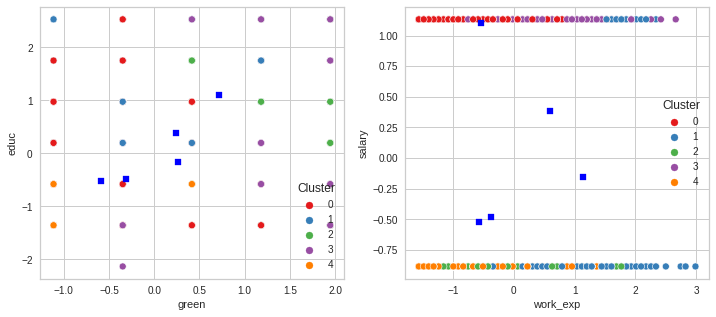

In [34]:
fig1, (axes) = plt.subplots(1,2,figsize=(12,5))


scat_1 = sns.scatterplot('green', 'educ', data=KM5_clustered,
                hue='Cluster', ax=axes[0], palette='Set1', legend='full')

sns.scatterplot('work_exp', 'salary', data=KM5_clustered,
                hue='Cluster', palette='Set1', ax=axes[1], legend='full')

axes[0].scatter(KM_5_clusters.cluster_centers_[:,1],KM_5_clusters.cluster_centers_[:,2], marker='s', s=40, c="blue")
axes[1].scatter(KM_5_clusters.cluster_centers_[:,0],KM_5_clusters.cluster_centers_[:,2], marker='s', s=40, c="blue")
plt.show()

In [44]:
KM_clust_sizes = KM5_clustered.groupby('Cluster').size().to_frame()
KM_clust_sizes.columns = ["KM_size"]
KM_clust_sizes

,KM_size
Cluster,
0,218
1,167
2,173
3,185
4,238


In [ ]:
# Кластеризация с нормировкой MinMax Scaler
data_clust1=df_minmax[['green', 'educ', 'work_exp', 'salary', 'climate']]
data_clust1.corr()
# Видим, что по методу MinMax корреляция среди переменных остается в пределах разумного, можем продолжать. 

,green,educ,work_exp,salary,climate
green,1.000000,0.066020,0.005207,0.008163,0.103931
educ,0.066020,1.000000,0.150832,-0.026888,-0.017106
work_exp,0.005207,0.150832,1.000000,0.030987,0.027617
salary,0.008163,-0.026888,0.030987,1.000000,0.042490
climate,0.103931,-0.017106,0.027617,0.042490,1.000000


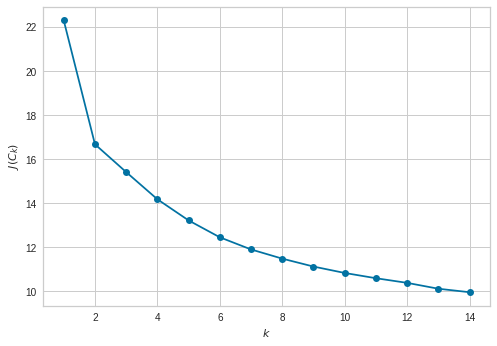

In [ ]:
from sklearn.cluster import KMeans

inertia = []
for k in range(1, 15):
    kmeans = KMeans(n_clusters=k, random_state=42).fit(data_clust1)
    inertia.append(np.sqrt(kmeans.inertia_))

plt.plot(range(1, 15), inertia, marker='o');
plt.xlabel('$k$')
plt.ylabel('$J(C_k)$');

Ихсодя из этого графика, хочется предположить, что оптимальное количество кластеров = 2, так как в этом значении происходит заметный перелдом графика.

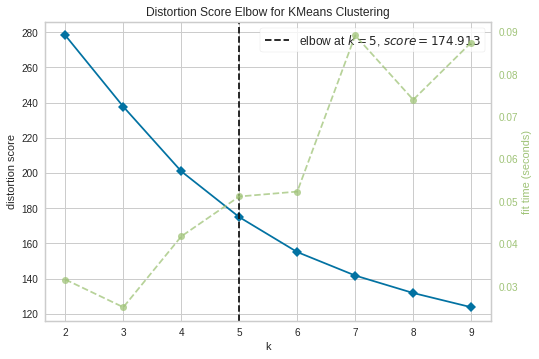

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

model = KMeans(random_state=1)
visualizer = KElbowVisualizer(model, k=(2,10))

visualizer.fit(data_clust1)
visualizer.show()
plt.show()

Данный график автоматически показывает нам, что оптимальным значением является k=5, согласно методу локтя. 

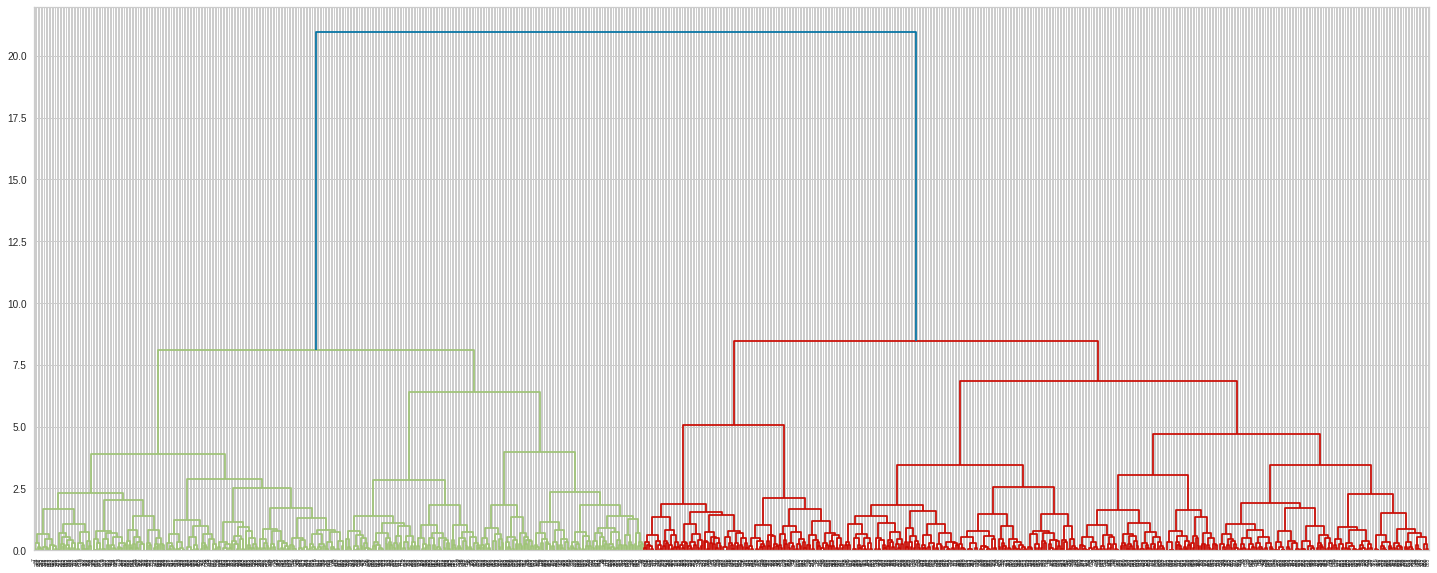

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(data_clust1, 'ward')
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)

Проведя разре по уровню 7,5 по ос у, получаем 4 кластера.

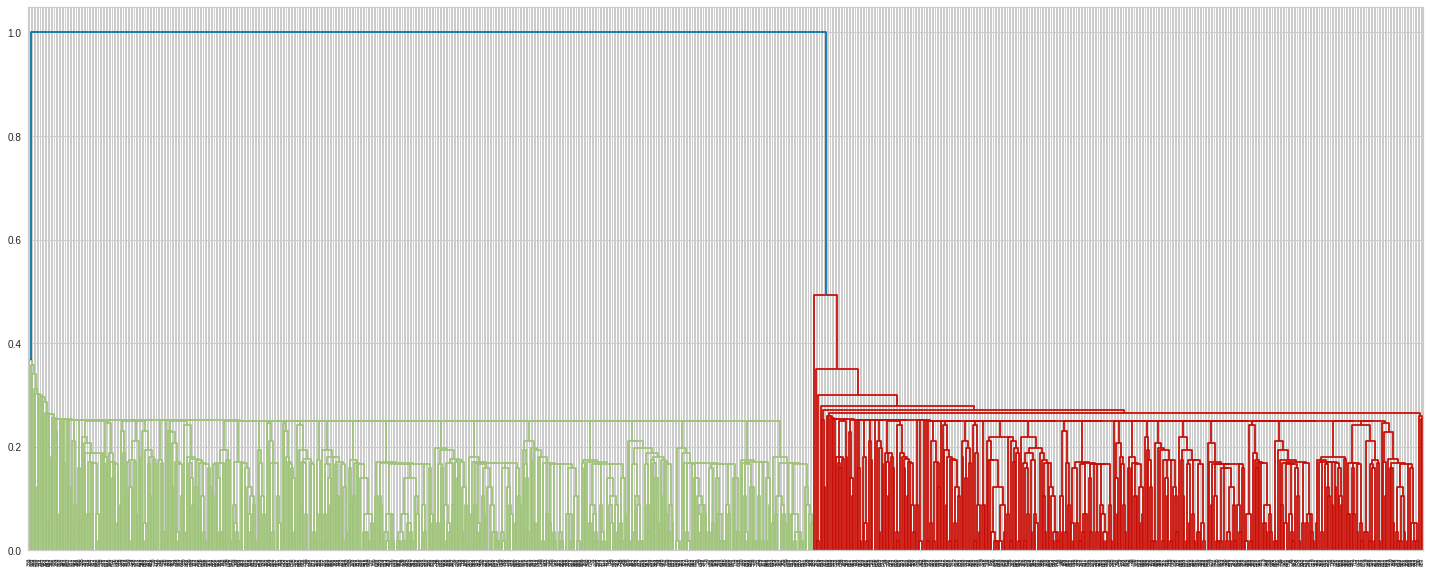

In [ ]:
Z = linkage(data_clust1, 'single')
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)

Проведя разрез по линии 0,4 получаем 3 кластера.

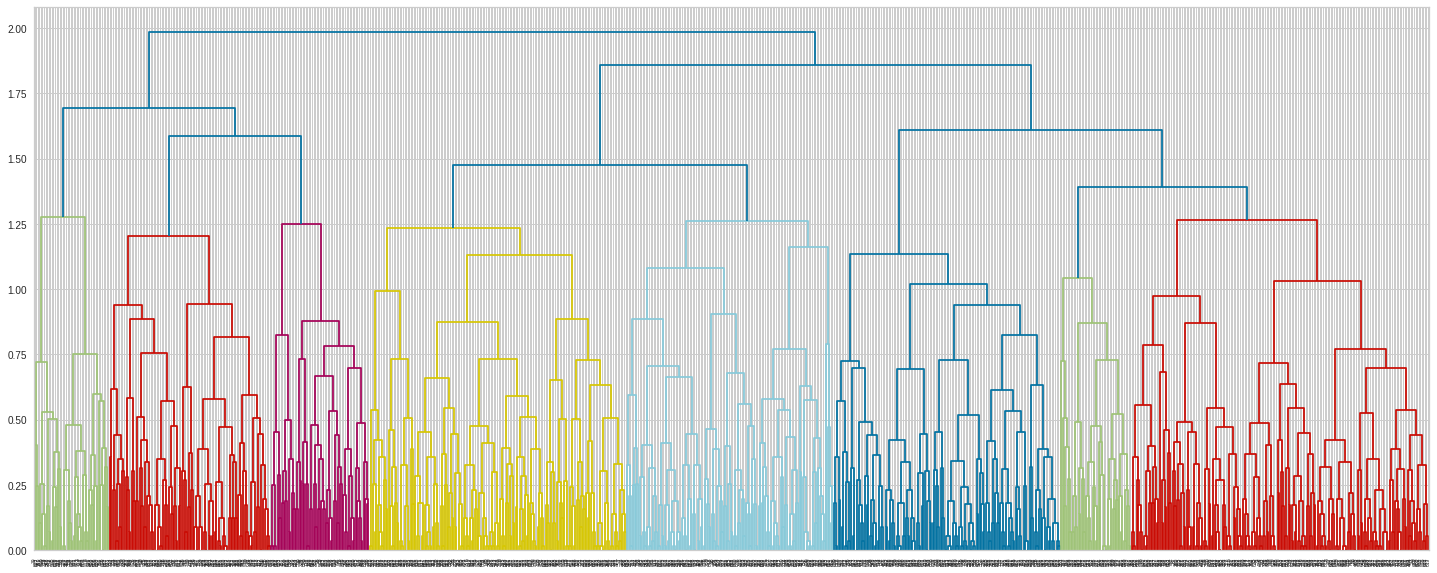

In [ ]:
Z = linkage(data_clust1, 'complete')
fig = plt.figure(figsize=(25, 10))
dn = dendrogram(Z)

Проведя разрез по линии 1,75 вновь получаем 3 кластера. 

Исходя из всех построенных выше графиков, моэжем сделать вывод, что оптимальным количеством кластеров станет именно 3, так как данное количество несколько раз повторялось при анализе графиков и близко к отличающимся значениям. 

Среднее значение силуэта для 5 кластеров: 0.3


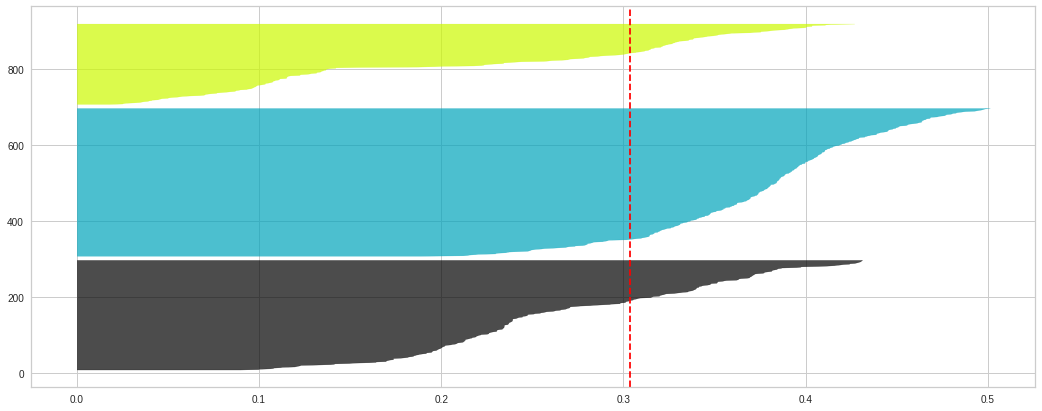

In [ ]:
fig, (ax1) = plt.subplots(1, 1)
fig.set_size_inches(18, 7)


clusterer = KMeans(n_clusters=3, random_state=10)
cluster_labels = clusterer.fit_predict(data_clust1)

silhouette_avg = silhouette_score(data_clust1, cluster_labels)
print("Среднее значение силуэта для 5 кластеров:", round(silhouette_avg,2))

sample_silhouette_values = silhouette_samples(data_clust1, cluster_labels)

y_lower = 10
for i in range(0, 3):
    ith_cluster_silhouette_values = \
         sample_silhouette_values[cluster_labels == i]

    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = cm.nipy_spectral(float(i) / 3)
    ax1.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)
    y_lower = y_upper + 10

ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

plt.show()

По графику видно, что все значения находятся в положительной зоне, значит, они далеко от соседних кластеров и, скорее всего, определены правильно. 

In [ ]:
# Интерпретация графика средних. Выбор и обоснование предпочтительной нормировки

In [ ]:
# Предложение мер по повышению эффективности работы сотрудников для каждого кластера

# Кластеризация DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN

In [ ]:
db = DBSCAN(eps=0.3, min_samples=10).fit(data_clust)

In [ ]:
# Подобрать такие значения eps и min_samples, чтобы число кластеров = числу выбранных кластеров
# в кластеризации к-средних

db = DBSCAN(eps=0.7, min_samples=5).fit(data_clust)
#core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
#core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_clusters_

5

In [ ]:
db.core_sample_indices_

array([  0,   1,   2,   3,   4,   6,   7,   9,  10,  11,  12,  13,  14,
        15,  16,  17,  18,  19,  21,  22,  24,  26,  27,  29,  30,  31,
        34,  36,  38,  39,  41,  42,  45,  47,  49,  50,  51,  52,  53,
        54,  56,  59,  60,  63,  66,  68,  70,  71,  75,  76,  78,  79,
        80,  82,  83,  84,  85,  87,  88,  89,  93,  94,  95,  97,  99,
       100, 102, 103, 104, 105, 106, 107, 108, 109, 114, 115, 117, 119,
       120, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 133, 134,
       135, 136, 137, 139, 141, 142, 143, 146, 148, 149, 151, 153, 154,
       156, 157, 158, 159, 162, 163, 164, 167, 168, 169, 170, 171, 173,
       175, 176, 178, 179, 180, 181, 182, 184, 185, 186, 187, 189, 190,
       192, 194, 195, 196, 197, 198, 199, 202, 203, 205, 206, 207, 208,
       209, 212, 215, 216, 217, 220, 221, 223, 225, 226, 227, 228, 229,
       230, 232, 235, 236, 237, 238, 240, 241, 245, 246, 247, 250, 251,
       252, 253, 256, 258, 259, 260, 262, 263, 266, 267, 268, 26

In [ ]:
db.labels_

array([ 0,  1,  0,  0,  0,  1,  0,  0,  4,  0,  0,  1,  1,  1,  1,  1,  0,
        0,  0,  1, -1,  0,  0, -1,  1, -1,  1,  1,  4,  0,  0,  1, -1,  1,
        0, -1,  0, -1,  1,  1,  0,  1,  1,  1, -1,  1,  0,  0,  0,  1,  1,
        1,  1,  1,  1,  1,  0,  1, -1,  0,  1,  0,  0,  1,  0,  0,  0, -1,
        1, -1,  1,  1,  0, -1, -1,  0,  1,  1,  0,  1,  1,  0,  1,  0,  1,
        1,  1,  1,  1,  0, -1, -1, -1,  1,  1,  1,  1,  0, -1,  1,  1,  1,
        1,  0,  0,  1,  1,  1,  1,  0, -1, -1,  0, -1,  0,  2,  0,  1, -1,
        1,  1, -1,  0,  1,  1,  1,  0,  0,  1,  0,  0,  1, -1,  1,  0,  0,
        3,  1,  0,  1, -1,  1,  1,  1, -1, -1,  0, -1,  1,  1, -1,  0,  1,
        0,  1,  1,  1,  1,  1,  1, -1, -1,  0,  1,  0, -1, -1,  1,  1,  0,
        1,  1, -1,  1,  0,  1,  1, -1,  1,  1,  1,  1,  0, -1,  0,  1,  1,
        1,  1,  0,  1, -1,  0,  0,  1,  1,  0,  4,  1,  1, -1, -1,  1,  1,
       -1,  0,  1,  1,  1,  1,  0, -1,  1,  1,  0,  1,  0,  0, -1, -1,  1,
        0,  1,  1, -1,  1

In [ ]:
# Построить график средних значений, дать экономическую интерпретацию и предложить меры 
# поддержки для каждого кластера. Сравнить с графиком средних k-means
# Выбрать наиболее удачный метод кластеризации